In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

In [2]:
DATA_DIR = Path(".")

xpt_files = sorted(DATA_DIR.glob("*.xpt"))

print("Bulunan dosya sayısı:", len(xpt_files))

for file in xpt_files:
    print(file.name)

Bulunan dosya sayısı: 19
ALB_CR_L.xpt
ALQ_L.xpt
BIOPRO_L.xpt
BMX_L.xpt
CBC_L.xpt
DEMO_L.xpt
DIQ_L.xpt
DR1TOT_L.xpt
DR2TOT_L.xpt
GHB_L.xpt
GLU_L.xpt
HDL_L.xpt
KIQ_U_L.xpt
MCQ_L.xpt
PAQ_L.xpt
SLQ_L.xpt
SMQ_L.xpt
TCHOL_L.xpt
TRIGLY_L.xpt


In [3]:
file_info = []

for file in xpt_files:
    df = pd.read_sas(file, format="xport")

    file_info.append({
        "Dosya": file.name,
        "Kişi/Kayıt Sayısı": len(df),
        "Feature Sayısı": len(df.columns),
        "SEQN Var mı": "SEQN" in df.columns
    })

file_info_df = pd.DataFrame(file_info)

display(
    file_info_df.sort_values(
        "Kişi/Kayıt Sayısı",
        ascending=False
    ).reset_index(drop=True)
)

,Dosya,Kişi/Kayıt Sayısı,Feature Sayısı,SEQN Var mı
0,DEMO_L.xpt,11933,27,True
1,DIQ_L.xpt,11744,9,True
2,MCQ_L.xpt,11744,35,True
3,SMQ_L.xpt,9015,9,True
4,DR2TOT_L.xpt,8860,85,True
5,BMX_L.xpt,8860,22,True
6,DR1TOT_L.xpt,8860,168,True
7,CBC_L.xpt,8727,23,True
8,SLQ_L.xpt,8501,7,True
9,ALB_CR_L.xpt,8493,8,True


In [4]:
for file in xpt_files:
    df = pd.read_sas(file, format="xport")

    print(f"\n{'=' * 50}")
    print(f"Dosya: {file.name}")
    print(f"Feature sayısı: {len(df.columns)}")
    print(df.columns.tolist())


Dosya: ALB_CR_L.xpt
Feature sayısı: 8
['SEQN', 'URXUMA', 'URXUMS', 'URDUMALC', 'URXUCR', 'URXCRS', 'URDUCRLC', 'URDACT']

Dosya: ALQ_L.xpt
Feature sayısı: 9
['SEQN', 'ALQ111', 'ALQ121', 'ALQ130', 'ALQ142', 'ALQ270', 'ALQ280', 'ALQ151', 'ALQ170']

Dosya: BIOPRO_L.xpt
Feature sayısı: 42
['SEQN', 'WTPH2YR', 'LBXSATSI', 'LBXSAL', 'LBDSALSI', 'LBXSAPSI', 'LBXSASSI', 'LBXSC3SI', 'LBXSBU', 'LBDSBUSI', 'LBXSCLSI', 'LBXSCK', 'LBXSCR', 'LBDSCRSI', 'LBXSGB', 'LBDSGBSI', 'LBXSGL', 'LBDSGLSI', 'LBXSGTSI', 'LBDSGTLC', 'LBXSIR', 'LBDSIRSI', 'LBXSLDSI', 'LBXMAGN', 'LBXSOSSI', 'LBXSPH', 'LBDSPHSI', 'LBXSKSI', 'LBXSNASI', 'LBXSTB', 'LBDSTBSI', 'LBDSTBLC', 'LBXSCA', 'LBDSCASI', 'LBXSCH', 'LBDSCHSI', 'LBXSTP', 'LBDSTPSI', 'LBXSTR', 'LBDSTRSI', 'LBXSUA', 'LBDSUASI']

Dosya: BMX_L.xpt
Feature sayısı: 22
['SEQN', 'BMDSTATS', 'BMXWT', 'BMIWT', 'BMXRECUM', 'BMIRECUM', 'BMXHEAD', 'BMIHEAD', 'BMXHT', 'BMIHT', 'BMXBMI', 'BMDBMIC', 'BMXLEG', 'BMILEG', 'BMXARML', 'BMIARML', 'BMXARMC', 'BMIARMC', 'BMXWAIST', 'BMIWA

In [5]:
# Diyabet değişkenleri
diq = pd.read_sas(DATA_DIR / "DIQ_L.xpt", format="xport")

print("DIQ_L - Diyabet değişkenleri")
print(diq.columns.tolist())

display(diq.head())

# Hastalık değişkenleri
mcq = pd.read_sas(DATA_DIR / "MCQ_L.xpt", format="xport")

print("\nMCQ_L - Sağlık durumu değişkenleri")
print(mcq.columns.tolist())

display(mcq.head())

DIQ_L - Diyabet değişkenleri
['SEQN', 'DIQ010', 'DID040', 'DIQ160', 'DIQ180', 'DIQ050', 'DID060', 'DIQ060U', 'DIQ070']


,SEQN,DIQ010,DID040,DIQ160,DIQ180,DIQ050,DID060,DIQ060U,DIQ070
0,130378.0,2.0,NaN,2.0,2.0,NaN,NaN,NaN,NaN
1,130379.0,2.0,NaN,2.0,1.0,NaN,NaN,NaN,NaN
2,130380.0,1.0,35.0,NaN,NaN,2.0,NaN,NaN,1.0
3,130381.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,130382.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN



MCQ_L - Sağlık durumu değişkenleri
['SEQN', 'MCQ010', 'MCQ035', 'MCQ040', 'MCQ050', 'AGQ030', 'MCQ053', 'MCQ149', 'MCQ160A', 'MCQ195', 'MCQ160B', 'MCQ160C', 'MCQ160D', 'MCQ160E', 'MCQ160F', 'MCQ160M', 'MCQ170M', 'MCQ160P', 'MCQ160L', 'MCQ170L', 'MCQ500', 'MCQ510A', 'MCQ510B', 'MCQ510C', 'MCQ510D', 'MCQ510E', 'MCQ510F', 'MCQ550', 'MCQ560', 'MCQ220', 'MCQ230A', 'MCQ230B', 'MCQ230C', 'MCQ230D', 'OSQ230']


,SEQN,MCQ010,MCQ035,MCQ040,MCQ050,AGQ030,MCQ053,MCQ149,MCQ160A,MCQ195,...,MCQ510E,MCQ510F,MCQ550,MCQ560,MCQ220,MCQ230A,MCQ230B,MCQ230C,MCQ230D,OSQ230
0,130378.0,2.0,NaN,NaN,NaN,2.0,2.0,NaN,1.0,2.0,...,NaN,NaN,2.0,2.0,2.0,NaN,NaN,NaN,NaN,2.0
1,130379.0,2.0,NaN,NaN,NaN,2.0,2.0,NaN,2.0,NaN,...,NaN,NaN,2.0,2.0,1.0,30.0,NaN,NaN,NaN,1.0
2,130380.0,2.0,NaN,NaN,NaN,2.0,2.0,NaN,2.0,NaN,...,NaN,NaN,2.0,2.0,2.0,NaN,NaN,NaN,NaN,1.0
3,130381.0,2.0,NaN,NaN,NaN,1.0,2.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,130382.0,2.0,NaN,NaN,NaN,2.0,2.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
# Diyabet target dağılımı
print("DIQ010 - Diyabet dağılımı")
print(diq["DIQ010"].value_counts(dropna=False).sort_index())

# MCQ hastalık target dağılımları
targets = [
    "MCQ160A",
    "MCQ160B",
    "MCQ160C",
    "MCQ160D",
    "MCQ160E",
    "MCQ160F",
    "MCQ160L",
    "MCQ160M",
    "MCQ160P",
    "MCQ220"
]

for col in targets:
    print(f"\n{col}")
    print(mcq[col].value_counts(dropna=False).sort_index())

DIQ010 - Diyabet dağılımı
DIQ010
1.0     1081
2.0    10371
3.0      284
9.0        4
NaN        4
Name: count, dtype: int64

MCQ160A
MCQ160A
1.0    2532
2.0    5258
9.0      17
NaN    3937
Name: count, dtype: int64

MCQ160B
MCQ160B
1.0     343
2.0    7448
9.0      17
NaN    3936
Name: count, dtype: int64

MCQ160C
MCQ160C
1.0     402
2.0    7371
9.0      34
NaN    3937
Name: count, dtype: int64

MCQ160D
MCQ160D
1.0     181
2.0    7602
9.0      25
NaN    3936
Name: count, dtype: int64

MCQ160E
MCQ160E
1.0     332
2.0    7462
9.0      13
NaN    3937
Name: count, dtype: int64

MCQ160F
MCQ160F
1.0     367
2.0    7418
9.0      21
NaN    3938
Name: count, dtype: int64

MCQ160L
MCQ160L
1.0     425
2.0    7369
7.0       2
9.0      11
NaN    3937
Name: count, dtype: int64

MCQ160M
MCQ160M
1.0    1053
2.0    6734
7.0       1
9.0      18
NaN    3938
Name: count, dtype: int64

MCQ160P
MCQ160P
1.0     567
2.0    7226
9.0      14
NaN    3937
Name: count, dtype: int64

MCQ220
MCQ220
1.0    1169
2.0   

In [7]:
target_cols = [
    "MCQ160A", "MCQ160B", "MCQ160C",
    "MCQ160D", "MCQ160E", "MCQ160F",
    "MCQ160L", "MCQ160M", "MCQ160P", "MCQ220"
]

rows = []

for col in target_cols:
    rows.append({
        "Hastalık değişkeni": col,
        "Evet (1)": (mcq[col] == 1).sum(),
        "Hayır (2)": (mcq[col] == 2).sum(),
        "Kod 9": (mcq[col] == 9).sum(),
        "Eksik": mcq[col].isna().sum()
    })

target_summary = pd.DataFrame(rows)
display(target_summary)

,Hastalık değişkeni,Evet (1),Hayır (2),Kod 9,Eksik
0,MCQ160A,2532,5258,17,3937
1,MCQ160B,343,7448,17,3936
2,MCQ160C,402,7371,34,3937
3,MCQ160D,181,7602,25,3936
4,MCQ160E,332,7462,13,3937
5,MCQ160F,367,7418,21,3938
6,MCQ160L,425,7369,11,3937
7,MCQ160M,1053,6734,18,3938
8,MCQ160P,567,7226,14,3937
9,MCQ220,1169,6631,5,3937


In [8]:
print("MCQ toplam kayıt:", len(mcq))

print(
    "MCQ160A eksik:",
    mcq["MCQ160A"].isna().sum()
)

print(
    "MCQ160A yanıt veren:",
    mcq["MCQ160A"].notna().sum()
)

print(
    "Tüm hastalık değişkenlerinde yanıt veren:",
    mcq[target_cols].notna().all(axis=1).sum()
)

MCQ toplam kayıt: 11744
MCQ160A eksik: 3937
MCQ160A yanıt veren: 7807
Tüm hastalık değişkenlerinde yanıt veren: 7805


In [9]:
bpq = pd.read_sas(DATA_DIR / "BPQ_L.xpt", format="xport")

print("BPQ kayıt sayısı:", len(bpq))
print("Değişkenler:", bpq.columns.tolist())

display(bpq.head())

BPQ kayıt sayısı: 8501
Değişkenler: ['SEQN', 'BPQ020', 'BPQ030', 'BPQ150', 'BPQ080', 'BPQ101D']


,SEQN,BPQ020,BPQ030,BPQ150,BPQ080,BPQ101D
0,130378.0,1.0,1.0,1.0,2.0,2.0
1,130379.0,1.0,1.0,1.0,2.0,2.0
2,130380.0,2.0,NaN,NaN,1.0,1.0
3,130384.0,2.0,NaN,NaN,2.0,2.0
4,130385.0,2.0,NaN,NaN,2.0,2.0


In [10]:
print("BPQ020 - Yüksek tansiyon tanısı")
print(bpq["BPQ020"].value_counts(dropna=False).sort_index())

print("\nBPQ030 - İlgili değişken")
print(bpq["BPQ030"].value_counts(dropna=False).sort_index())

print("\nBPQ080 - Yüksek kolesterol tanısı")
print(bpq["BPQ080"].value_counts(dropna=False).sort_index())

BPQ020 - Yüksek tansiyon tanısı
BPQ020
1.0    2969
2.0    5518
7.0       1
9.0      10
NaN       3
Name: count, dtype: int64

BPQ030 - İlgili değişken
BPQ030
1.0    2468
2.0     474
7.0       1
9.0      25
NaN    5533
Name: count, dtype: int64

BPQ080 - Yüksek kolesterol tanısı
BPQ080
1.0    3096
2.0    5348
7.0       1
9.0      53
NaN       3
Name: count, dtype: int64


In [11]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path(".")

xpt_files = sorted(DATA_DIR.glob("*.xpt"))

duplicate_info = []

for file in xpt_files:
    df = pd.read_sas(file, format="xport")

    duplicate_info.append({
        "Dosya": file.name,
        "Satır Sayısı": len(df),
        "Benzersiz SEQN": df["SEQN"].nunique(),
        "Tekrarlı SEQN": df["SEQN"].duplicated().sum()
    })

duplicate_df = pd.DataFrame(duplicate_info)

display(
    duplicate_df.sort_values(
        "Tekrarlı SEQN",
        ascending=False
    ).reset_index(drop=True)
)

,Dosya,Satır Sayısı,Benzersiz SEQN,Tekrarlı SEQN
0,ALB_CR_L.xpt,8493,8493,0
1,ALQ_L.xpt,6337,6337,0
2,BIOPRO_L.xpt,7199,7199,0
3,BMX_L.xpt,8860,8860,0
4,BPQ_L.xpt,8501,8501,0
5,CBC_L.xpt,8727,8727,0
6,DEMO_L.xpt,11933,11933,0
7,DIQ_L.xpt,11744,11744,0
8,DR1TOT_L.xpt,8860,8860,0
9,DR2TOT_L.xpt,8860,8860,0


In [12]:

from pathlib import Path
import pandas as pd

DATA_DIR = Path(".")

xpt_files = sorted(DATA_DIR.glob("*.xpt"))

column_sources = {}

for file in xpt_files:
    df = pd.read_sas(file, format="xport")

    for col in df.columns:
        column_sources.setdefault(col, []).append(file.name)

# Birden fazla dosyada bulunan sütunlar
duplicate_columns = {
    col: files
    for col, files in column_sources.items()
    if len(files) > 1 and col != "SEQN"
}

print("Birden fazla dosyada bulunan sütunlar:")

for col, files in duplicate_columns.items():
    print(f"{col}: {files}")


Birden fazla dosyada bulunan sütunlar:
WTPH2YR: ['BIOPRO_L.xpt', 'CBC_L.xpt', 'GHB_L.xpt', 'HDL_L.xpt', 'TCHOL_L.xpt']
WTDRD1: ['DR1TOT_L.xpt', 'DR2TOT_L.xpt']
WTDR2D: ['DR1TOT_L.xpt', 'DR2TOT_L.xpt']
DRABF: ['DR1TOT_L.xpt', 'DR2TOT_L.xpt']
DRDINT: ['DR1TOT_L.xpt', 'DR2TOT_L.xpt']
WTSAF2YR: ['GLU_L.xpt', 'TRIGLY_L.xpt']


In [13]:

from pathlib import Path
import pandas as pd

DATA_DIR = Path(".")

# Ana tablo
merged_df = pd.read_sas(
    DATA_DIR / "DEMO_L.xpt",
    format="xport"
)

# İlk aşamada birleştireceğimiz dosyalar
files_to_merge = [
    "DIQ_L.xpt",
    "MCQ_L.xpt",
    "BPQ_L.xpt",
    "BMX_L.xpt",
    "ALQ_L.xpt",
    "PAQ_L.xpt",
    "SLQ_L.xpt",
    "SMQ_L.xpt",
]

for filename in files_to_merge:
    df = pd.read_sas(
        DATA_DIR / filename,
        format="xport"
    )

    # Birleştirmenin güvenli olduğunu doğrula
    assert df["SEQN"].is_unique, (
        f"{filename} dosyasında tekrarlı SEQN var."
    )

    # SEQN üzerinden katılımcıları eşleştir
    merged_df = merged_df.merge(
        df,
        on="SEQN",
        how="left",
        validate="one_to_one",
        suffixes=("", "_duplicate")
    )

    print(
        f"{filename} eklendi | "
        f"Satır: {len(merged_df)} | "
        f"Sütun: {len(merged_df.columns)}"
    )

print("\nBirleştirme tamamlandı.")
print("Son veri seti boyutu:", merged_df.shape)
print("Benzersiz katılımcı:", merged_df["SEQN"].nunique())


DIQ_L.xpt eklendi | Satır: 11933 | Sütun: 35
MCQ_L.xpt eklendi | Satır: 11933 | Sütun: 69
BPQ_L.xpt eklendi | Satır: 11933 | Sütun: 74
BMX_L.xpt eklendi | Satır: 11933 | Sütun: 95
ALQ_L.xpt eklendi | Satır: 11933 | Sütun: 103
PAQ_L.xpt eklendi | Satır: 11933 | Sütun: 110
SLQ_L.xpt eklendi | Satır: 11933 | Sütun: 116
SMQ_L.xpt eklendi | Satır: 11933 | Sütun: 124

Birleştirme tamamlandı.
Son veri seti boyutu: (11933, 124)
Benzersiz katılımcı: 11933


In [14]:

# Her sütundaki eksik değer sayısı ve oranı
missing_df = pd.DataFrame({
    "Eksik Sayısı": merged_df.isna().sum(),
    "Eksik Oranı (%)": (
        merged_df.isna().mean() * 100
    ).round(2)
})

# En fazla eksik değere sahip sütunlar
missing_df = missing_df.sort_values(
    "Eksik Oranı (%)",
    ascending=False
)

display(missing_df.head(30))


,Eksik Sayısı,Eksik Oranı (%)
BMIHEAD,11933,100.00
MCQ230D,11931,99.98
MCQ510B,11929,99.97
MCQ510E,11917,99.87
BMIRECUM,11915,99.85
SMD630,11910,99.81
MCQ230C,11907,99.78
MCQ510C,11886,99.61
MCQ510D,11871,99.48
BMXHEAD,11863,99.41


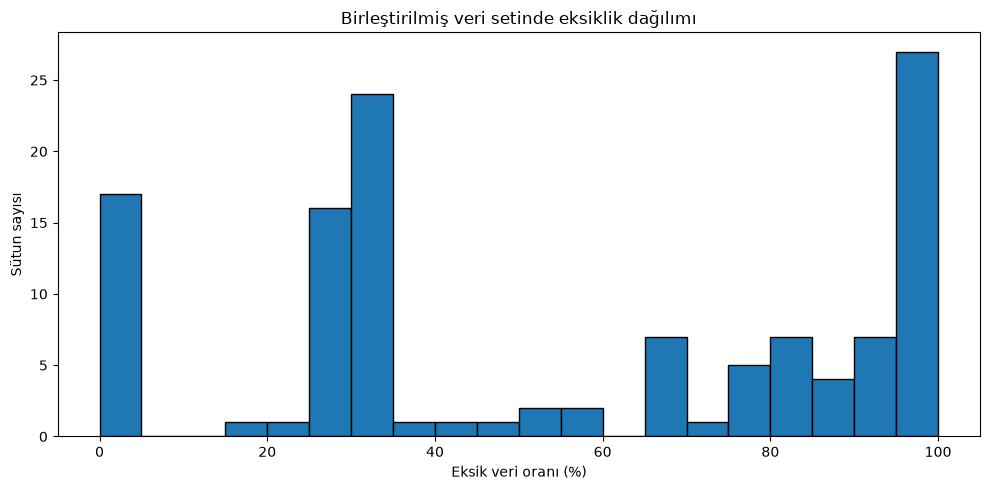

Toplam sütun: 124
Eksiksiz sütun: 12
Eksikliği %50'den fazla sütun: 62
Eksikliği %90'dan fazla sütun: 34


In [15]:

import matplotlib.pyplot as plt

missing_percent = (
    merged_df.isna().mean() * 100
).sort_values(ascending=False)

plt.figure(figsize=(10, 5))
plt.hist(
    missing_percent,
    bins=20,
    edgecolor="black"
)

plt.xlabel("Eksik veri oranı (%)")
plt.ylabel("Sütun sayısı")
plt.title("Birleştirilmiş veri setinde eksiklik dağılımı")
plt.tight_layout()
plt.show()

print("Toplam sütun:", len(merged_df.columns))
print("Eksiksiz sütun:", (missing_percent == 0).sum())
print("Eksikliği %50'den fazla sütun:", (missing_percent > 50).sum())
print("Eksikliği %90'dan fazla sütun:", (missing_percent > 90).sum())


In [16]:

candidate_features = [
    "RIDAGEYR",  # Yaş
    "RIAGENDR",  # Cinsiyet
    "RIDRETH3",  # Irk/etnik grup kodu
    "DMDEDUC2",  # Eğitim düzeyi
    "INDFMPIR",  # Gelir-yoksulluk oranı
    "BMXWT",     # Ağırlık
    "BMXHT",     # Boy
    "BMXBMI",    # Vücut kitle indeksi
    "BMXWAIST",  # Bel çevresi
    "BPQ020",    # Yüksek tansiyon tanısı
    "BPQ080",    # Yüksek kolesterol tanısı
    "DIQ010",    # Diyabet tanısı
    "PAQ605",    # Şiddetli iş/aktivite düzeyiyle ilişkili değişken
    "SLD012",    # İş günleri/okul günleri uyku süresi
    "SMQ020",    # En az 100 sigara içme geçmişi
]

available_features = [
    col for col in candidate_features
    if col in merged_df.columns
]

feature_check = pd.DataFrame({
    "Değişken": available_features,
    "Eksik Sayısı": [
        merged_df[col].isna().sum()
        for col in available_features
    ],
    "Eksik Oranı (%)": [
        round(merged_df[col].isna().mean() * 100, 2)
        for col in available_features
    ],
    "Benzersiz Değer Sayısı": [
        merged_df[col].nunique(dropna=True)
        for col in available_features
    ]
})

display(feature_check)


,Değişken,Eksik Sayısı,Eksik Oranı (%),Benzersiz Değer Sayısı
0,RIDAGEYR,0,0.00,81
1,RIAGENDR,0,0.00,2
2,RIDRETH3,0,0.00,6
3,DMDEDUC2,4139,34.69,6
4,INDFMPIR,2041,17.10,471
5,BMXWT,3179,26.64,1389
6,BMXHT,3434,28.78,995
7,BMXBMI,3462,29.01,451
8,BMXWAIST,3743,31.37,1049
9,BPQ020,3435,28.79,4


In [17]:

targets = {
    "Diyabet": "DIQ010",
    "Hipertansiyon": "BPQ020",
    "Yüksek kolesterol": "BPQ080"
}

for name, column in targets.items():
    valid = merged_df[column].isin([1, 2])
    target = merged_df.loc[valid, column]

    yes_count = (target == 1).sum()
    no_count = (target == 2).sum()
    total = len(target)

    print(f"\n--- {name} ---")
    print("Geçerli katılımcı:", total)
    print(f"Evet: {yes_count} (%{yes_count / total * 100:.2f})")
    print(f"Hayır: {no_count} (%{no_count / total * 100:.2f})")



--- Diyabet ---
Geçerli katılımcı: 11452
Evet: 1081 (%9.44)
Hayır: 10371 (%90.56)

--- Hipertansiyon ---
Geçerli katılımcı: 8487
Evet: 2969 (%34.98)
Hayır: 5518 (%65.02)

--- Yüksek kolesterol ---
Geçerli katılımcı: 8444
Evet: 3096 (%36.67)
Hayır: 5348 (%63.33)


In [18]:

# Hipertansiyon için başlangıç özellik adayları
candidate_features = [
    "RIDAGEYR",   # Yaş
    "RIAGENDR",   # Cinsiyet
    "RIDRETH3",   # Etnik grup
    "DMDEDUC2",   # Eğitim düzeyi
    "INDFMPIR",   # Gelir/yoksulluk oranı
    "BMXBMI",     # Vücut kitle indeksi
    "BMXWAIST",   # Bel çevresi
    "SLD012",     # Uyku süresi
    "SMQ020",     # Sigara içme geçmişi
    "PAQ605",     # Fiziksel aktivite değişkeni
    "BPQ080",     # Yüksek kolesterol tanısı
]

target_col = "BPQ020"

available_features = [
    col for col in candidate_features
    if col in merged_df.columns
]

feature_report = pd.DataFrame({
    "Değişken": available_features,
    "Eksik Oranı (%)": [
        round(merged_df[col].isna().mean() * 100, 2)
        for col in available_features
    ],
    "Benzersiz Değer": [
        merged_df[col].nunique(dropna=True)
        for col in available_features
    ]
})

display(feature_report)


,Değişken,Eksik Oranı (%),Benzersiz Değer
0,RIDAGEYR,0.00,81
1,RIAGENDR,0.00,2
2,RIDRETH3,0.00,6
3,DMDEDUC2,34.69,6
4,INDFMPIR,17.10,471
5,BMXBMI,29.01,451
6,BMXWAIST,31.37,1049
7,SLD012,29.71,24
8,SMQ020,31.83,4
9,BPQ080,28.79,4


In [19]:

feature_cols = [
    "RIDAGEYR",
    "RIAGENDR",
    "RIDRETH3",
    "DMDEDUC2",
    "INDFMPIR",
    "BMXBMI",
    "BMXWAIST",
    "SLD012",
    "SMQ020",
]

target_col = "BPQ020"

# Yalnızca geçerli hipertansiyon yanıtları: 1 = Evet, 2 = Hayır
valid_mask = merged_df[target_col].isin([1, 2])

X = merged_df.loc[valid_mask, feature_cols].copy()

# Hedefi 1 = hipertansiyon var, 0 = hipertansiyon yok yap
y = (
    merged_df.loc[valid_mask, target_col]
    .map({1: 1, 2: 0})
    .astype(int)
)

print("X boyutu:", X.shape)
print("y boyutu:", y.shape)
print("\nHedef dağılımı:")
print(y.value_counts().rename(index={1: "Hipertansiyon var", 0: "Hipertansiyon yok"}))
print("\nÖzelliklerde eksik değer sayısı:")
print(X.isna().sum())


X boyutu: (8487, 9)
y boyutu: (8487,)

Hedef dağılımı:
BPQ020
Hipertansiyon yok    5518
Hipertansiyon var    2969
Name: count, dtype: int64

Özelliklerde eksik değer sayısı:
RIDAGEYR       0
RIAGENDR       0
RIDRETH3       0
DMDEDUC2     704
INDFMPIR    1431
BMXBMI      1979
BMXWAIST    2204
SLD012       109
SMQ020       363
dtype: int64


In [20]:

categorical_cols = [
    "RIAGENDR",
    "RIDRETH3",
    "DMDEDUC2",
    "SMQ020",
]

for col in categorical_cols:
    print(f"\n--- {col} ---")
    print(X[col].value_counts(dropna=False).sort_index())



--- RIAGENDR ---
RIAGENDR
1.0    3821
2.0    4666
Name: count, dtype: int64

--- RIDRETH3 ---
RIDRETH3
1.0     657
2.0     879
3.0    4830
4.0    1089
6.0     463
7.0     569
Name: count, dtype: int64

--- DMDEDUC2 ---
DMDEDUC2
1.0     373
2.0     666
3.0    1749
4.0    2367
5.0    2617
9.0      11
NaN     704
Name: count, dtype: int64

--- SMQ020 ---
SMQ020
1.0    3240
2.0    4870
7.0       7
9.0       7
NaN     363
Name: count, dtype: int64


In [21]:

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

# Verinin kopyasını al
X_model = X.copy()

# Özel yanıt kodlarını eksik değer olarak işaretle
X_model["DMDEDUC2"] = X_model["DMDEDUC2"].replace([7, 9], float("nan"))
X_model["SMQ020"] = X_model["SMQ020"].replace([7, 9], float("nan"))

numeric_cols = [
    "INDFMPIR",
    "BMXBMI",
    "BMXWAIST",
    "SLD012",
]

categorical_cols = [
    "RIAGENDR",
    "RIDRETH3",
    "DMDEDUC2",
    "SMQ020",
]

# Eğitim/test ayrımı
X_train, X_test, y_train, y_test = train_test_split(
    X_model,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Sayısal özelliklerde medyan, kategoriklerde en sık değer
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols),
    ("age", "passthrough", ["RIDAGEYR"]),
])

# İlk model
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

print("Eğitim örneği:", len(X_train))
print("Test örneği:", len(X_test))
print("Model eğitildi.")


Eğitim örneği: 6789
Test örneği: 1698
Model eğitildi.


In [22]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Test verisi üzerinde tahmin
y_pred = model.predict(X_test)

# Hipertansiyon sınıfına ait olasılık
y_proba = model.predict_proba(X_test)[:, 1]

# Performans metrikleri
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1-score:", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_proba), 4))

print("\nSınıflandırma raporu:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Hipertansiyon yok", "Hipertansiyon var"]
))

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))


Accuracy: 0.7279
Precision: 0.615
Recall: 0.5943
F1-score: 0.6045
ROC-AUC: 0.7842

Sınıflandırma raporu:
                   precision    recall  f1-score   support

Hipertansiyon yok       0.79      0.80      0.79      1104
Hipertansiyon var       0.61      0.59      0.60       594

         accuracy                           0.73      1698
        macro avg       0.70      0.70      0.70      1698
     weighted avg       0.73      0.73      0.73      1698

Confusion matrix:
[[883 221]
 [241 353]]


In [23]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_proba = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest sonuçları")
print("Accuracy:", round(accuracy_score(y_test, rf_pred), 4))
print("Precision:", round(precision_score(y_test, rf_pred), 4))
print("Recall:", round(recall_score(y_test, rf_pred), 4))
print("F1-score:", round(f1_score(y_test, rf_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, rf_proba), 4))


Random Forest sonuçları
Accuracy: 0.7061
Precision: 0.5566
Recall: 0.7862
F1-score: 0.6518
ROC-AUC: 0.7773


In [24]:

from sklearn.metrics import confusion_matrix, classification_report

print("Confusion matrix:")
print(confusion_matrix(y_test, rf_pred))

print("\nSınıflandırma raporu:")
print(classification_report(
    y_test,
    rf_pred,
    target_names=["Hipertansiyon yok", "Hipertansiyon var"]
))


Confusion matrix:
[[732 372]
 [127 467]]

Sınıflandırma raporu:
                   precision    recall  f1-score   support

Hipertansiyon yok       0.85      0.66      0.75      1104
Hipertansiyon var       0.56      0.79      0.65       594

         accuracy                           0.71      1698
        macro avg       0.70      0.72      0.70      1698
     weighted avg       0.75      0.71      0.71      1698



In [25]:

import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

rf_proba = rf_model.predict_proba(X_test)[:, 1]

threshold_results = []

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:
    pred = (rf_proba >= threshold).astype(int)

    threshold_results.append({
        "Eşik": threshold,
        "Precision": precision_score(
            y_test, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, pred, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(3))


,Eşik,Precision,Recall,F1-score
0,0.30,0.474,0.907,0.623
1,0.35,0.499,0.889,0.639
2,0.40,0.516,0.857,0.644
3,0.45,0.531,0.820,0.645
4,0.50,0.557,0.786,0.652
5,0.55,0.565,0.727,0.636
6,0.60,0.580,0.625,0.601


In [26]:

import pandas as pd

# Ön işleme sonrası özellik isimleri
feature_names = (
    rf_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

# Random Forest özellik önemleri
importances = (
    rf_model.named_steps["classifier"]
    .feature_importances_
)

importance_df = pd.DataFrame({
    "Özellik": feature_names,
    "Önem": importances
}).sort_values("Önem", ascending=False)

display(importance_df.head(15).round(4))


,Özellik,Önem
19,age__RIDAGEYR,0.4393
2,numeric__BMXWAIST,0.1433
1,numeric__BMXBMI,0.1240
0,numeric__INDFMPIR,0.0827
3,numeric__SLD012,0.0597
16,categorical__DMDEDUC2_5.0,0.0285
18,categorical__SMQ020_2.0,0.0150
17,categorical__SMQ020_1.0,0.0141
9,categorical__RIDRETH3_4.0,0.0126
8,categorical__RIDRETH3_3.0,0.0122


In [27]:

try:
    import shap
    print("SHAP sürümü:", shap.__version__)
except ImportError:
    print("SHAP kurulu değil. Kurulum gerekli.")


SHAP kurulu değil. Kurulum gerekli.


In [28]:
%pip install shap

  Using cached slicer-0.0.8-py3-none-any.whl.metadata (4.0 kB)
   ---------------------------------------- 0.0/755.4 kB ? eta -:--:--
   ---------------------------------------- 0.0/755.4 kB ? eta -:--:--
   ---------------------------------------- 0.0/755.4 kB ? eta -:--:--
   ---------------------------------------- 0.0/755.4 kB ? eta -:--:--
   ---------------------------------------- 0.0/755.4 kB ? eta -:--:--
   ---------------------------------------- 0.0/755.4 kB ? eta -:--:--
   ---------------------------------------- 0.0/755.4 kB ? eta -:--:--
   ---------------------------------------- 0.0/755.4 kB ? eta -:--:--
   ---------------------------------------- 0.0/755.4 kB ? eta -:--:--
   ---------------------------------------- 0.0/755.4 kB ? eta -:--:--
   ---------------------------------------- 0.0/755.4 kB ? eta -:--:--
   ---------------------------------------- 0.0/755.4 kB ? eta -:--:--
   ------------- -------------------------- 262.1/755.4 kB ? eta -:--:--
   ---------

In [29]:
import shap

print("SHAP sürümü:", shap.__version__)

c:\BitirmeProjesi\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP sürümü: 0.53.0


In [30]:

import shap
import pandas as pd
import matplotlib.pyplot as plt

# Test verisinden örneklem seç
X_shap = X_test.sample(
    n=min(200, len(X_test)),
    random_state=42
)

# Modelin ön işleme adımlarını uygula
X_shap_transformed = (
    rf_model.named_steps["preprocessor"]
    .transform(X_shap)
)

# Dönüştürülmüş sütun isimleri
feature_names = (
    rf_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

# Eğitilmiş Random Forest
rf_classifier = rf_model.named_steps["classifier"]

# SHAP açıklayıcısı
explainer = shap.TreeExplainer(rf_classifier)

# SHAP değerleri
shap_values = explainer.shap_values(
    X_shap_transformed
)

print("SHAP hesaplaması tamamlandı.")
print("Dönüştürülmüş veri boyutu:", X_shap_transformed.shape)
print("SHAP değerlerinin boyutu:", getattr(shap_values, "shape", None))


SHAP hesaplaması tamamlandı.
Dönüştürülmüş veri boyutu: (200, 20)
SHAP değerlerinin boyutu: (200, 20, 2)


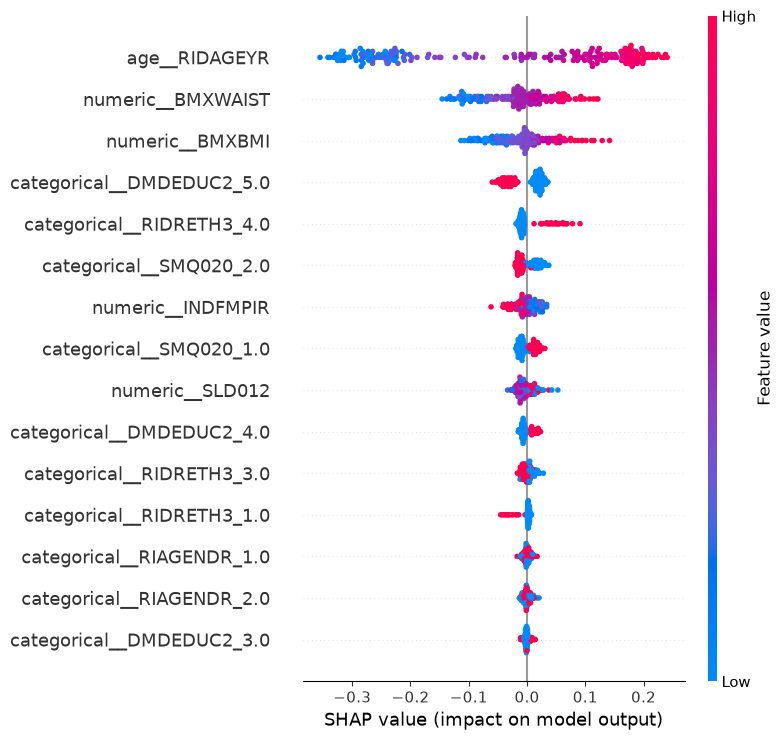

In [31]:

# Hipertansiyon var sınıfının SHAP değerleri
shap_values_positive = shap_values[:, :, 1]

# Genel özellik etkilerini göster
shap.summary_plot(
    shap_values_positive,
    X_shap_transformed,
    feature_names=feature_names,
    max_display=15,
    show=True
)


Gerçek etiket: 0
Model tahmini: Hipertansiyon var
Modelin pozitif sınıf olasılığı: 0.743


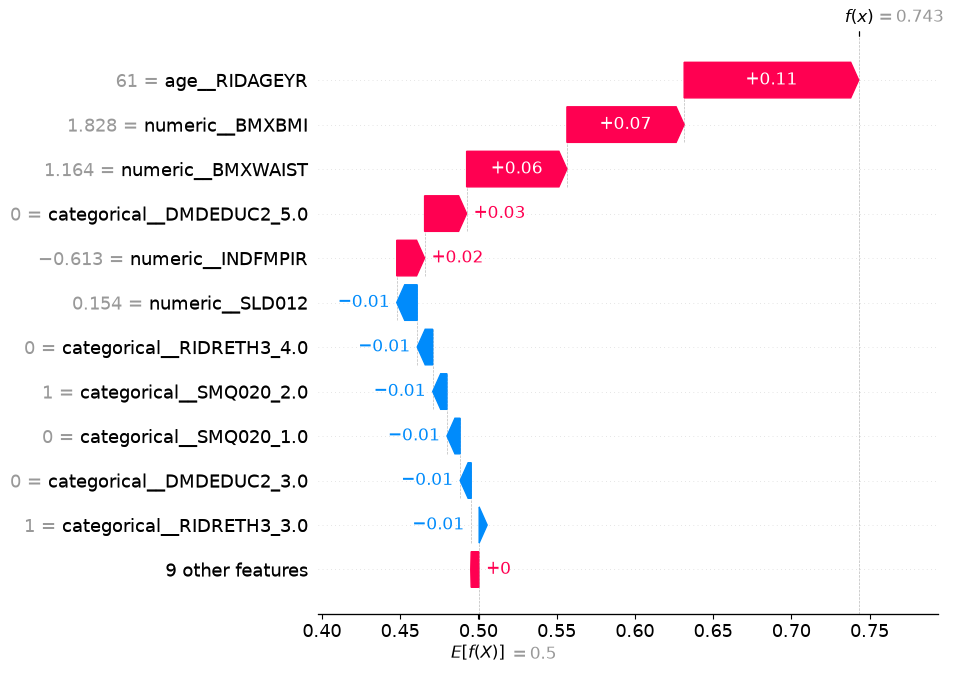

In [34]:

# Açıklamak için bir test katılımcısı seç
sample_index = 0

sample = X_shap.iloc[[sample_index]]
sample_transformed = X_shap_transformed[sample_index:sample_index + 1]

# Model tahmini ve olasılığı
prediction = rf_model.predict(sample)[0]
probability = rf_model.predict_proba(sample)[0, 1]

print("Gerçek etiket:", y_test.loc[sample.index[0]]
      if sample.index[0] in y_test.index else "Bu örnek y_test indeksinde değil")

print("Model tahmini:", "Hipertansiyon var" if prediction == 1
      else "Hipertansiyon yok")
print("Modelin pozitif sınıf olasılığı:", round(probability, 3))

# Tek katılımcının SHAP açıklaması

# Pozitif sınıf için SHAP açıklamasını oluştur
single_explanation = shap.Explanation(
    values=shap_values_positive[sample_index],
    base_values=explainer.expected_value[1],
    data=sample_transformed[0],
    feature_names=feature_names
)

shap.plots.waterfall(
    single_explanation,
    max_display=12
)

